# Four norms for finite-horizon control

The supplied endpoint-constrained system has four distinct control norms. A terminal-controllability SVD independently verifies minimum energy; a HiGHS LP verifies elementwise L1. Nonunique solutions are compared by objective and feasibility.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## One-step analytical system

In [2]:
from optimization_lab.convex_cases import regulator
p=dict(A=[[1.]],B=[[1.]],x_init=[1.],n=1,m=1,T=1)
r=regulator(p)
assert all(abs(row["clarabel"]["objective"]-1.)<1e-6 for row in r["rows"])
pd.DataFrame(r["rows"])

,objective,clarabel,independent_reference_objective,reference_type,objective_difference,forward_simulation_terminal_residual,energy,max_action_norm
0,frobenius,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",1.0,independent SVD least-energy solution,1.110223e-16,1.110223e-16,1.0,1.0
1,group_sum,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",1.0,SCS reference on identical declared cone model,4.148804e-11,1.143530e-14,1.0,1.0
2,group_peak,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",1.0,SCS reference on identical declared cone model,3.413543e-09,8.104628e-15,1.0,1.0
3,element_l1,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",1.0,independent terminal-map HiGHS LP,1.143530e-14,1.143530e-14,1.0,1.0


## Original hundred-step study

In [3]:
m=read("results/reference/convex/regulator/metrics.json")
assert max(r["forward_simulation_terminal_residual"] for r in m["rows"])<1e-7
pd.DataFrame(m["rows"])

,objective,clarabel,independent_reference_objective,reference_type,objective_difference,forward_simulation_terminal_residual,energy,max_action_norm
0,frobenius,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",0.927092,independent SVD least-energy solution,2.775558e-15,9.252527e-15,0.859500,0.179141
1,group_sum,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",5.996854,SCS reference on identical declared cone model,2.684040e-07,3.179702e-11,16.917587,3.829740
2,group_peak,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",0.110472,SCS reference on identical declared cone model,1.690402e-06,1.630293e-14,1.220365,0.110470
3,element_l1,"{'solver': 'CLARABEL', 'status': 'optimal', 'o...",7.044289,independent terminal-map HiGHS LP,1.366411e-08,1.209449e-14,30.384397,5.260188


## Controls and state trajectories

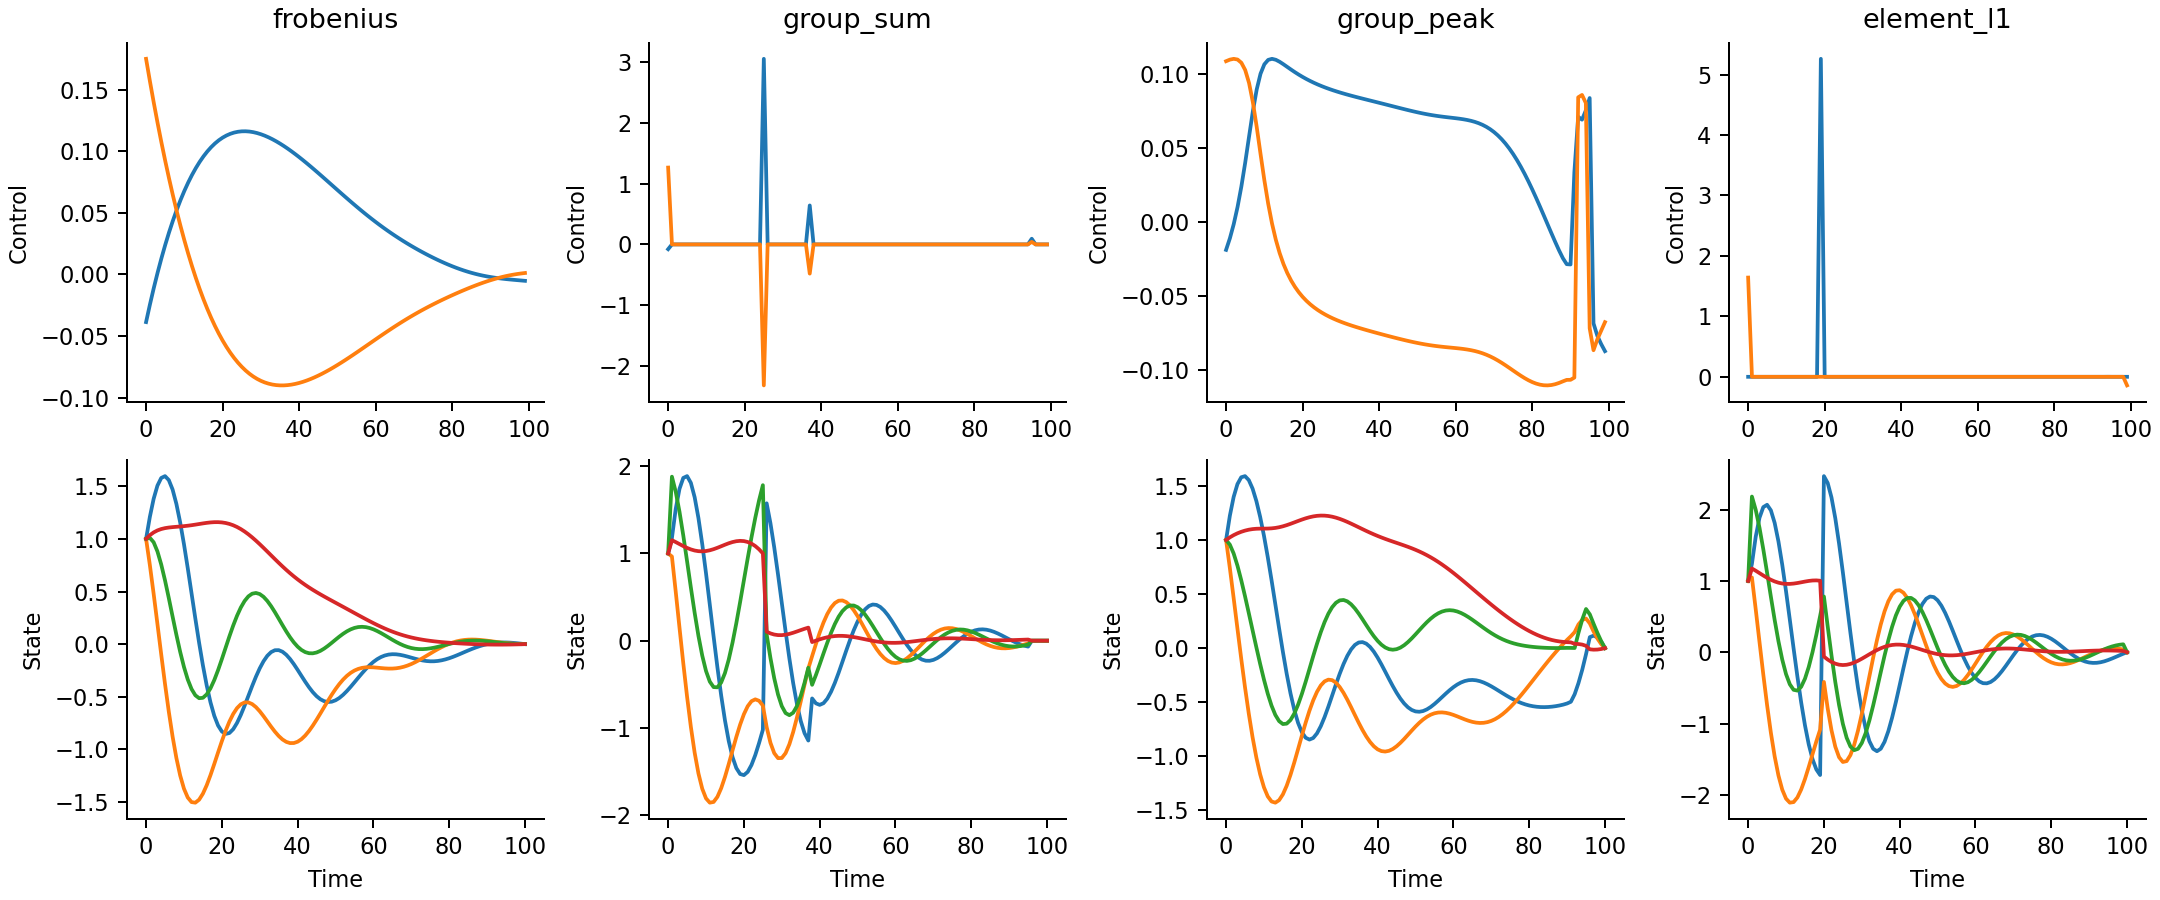

In [4]:
figure("regulator_norms")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.